# SLIP vs Mutascape

SLIP generates synthetic fitness landscapes from Potts models parameterised by
MSA-derived couplings. This notebook uses SLIP's actual `PottsModel` class
(from `external/slip/`, Apache-2.0, Google Research) and its published tuning
procedure to construct landscapes for GB1, TrpB4 and PhoQ, then compares
against Mutascape. RBD-S309 is excluded because its binary encoding is
incompatible with SLIP's amino acid Potts model.

Couplings are pointwise mutual information (log-odds), not direct coupling
analysis.

**Metrics:**
- **Walsh-spectrum distance** measures how well a synthetic landscape
  reproduces the proportions of first-, second- and third-order epistatic
  variance in the experimental landscape. Lower is better; 0 means identical
  spectral structure.
- **Spearman ρ / Kendall τ** measure rank correlation between synthetic and
  experimental fitness across held-out multi-mutant genotypes. Higher is
  better; 0 means no predictive value.

In [1]:
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.linalg import hadamard
from scipy.stats import spearmanr, kendalltau, theilslopes

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Shim for experiment module (avoids tensorflow dependency in SLIP's experiment.py)
_experiment = types.ModuleType("experiment")
def _get_fitness_df(sequences, fitness_fn, ref_seq):
    sequences = np.array(sequences)
    num_mutations = [sum(int(a != b) for a, b in zip(ref_seq, s)) for s in sequences.tolist()]
    return pd.DataFrame({"sequence": sequences.tolist(), "num_mutations": num_mutations, "fitness": fitness_fn(sequences)})
_experiment.get_fitness_df = _get_fitness_df
sys.modules["experiment"] = _experiment

sys.path.insert(0, str(REPO / "external" / "slip"))
import potts_model
import tuning as slip_tuning

from mutascape.mutant import AMINO_ACIDS

plt.rcParams.update({
    "figure.dpi": 130,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

OUT = REPO / "results" / "manuscript_v2_20261015"
RESULTS = REPO / "output" / "slip_comparison"
RESULTS.mkdir(parents=True, exist_ok=True)
AA_TO_IDX = {aa: i for i, aa in enumerate(AMINO_ACIDS)}
MSA_PATH = REPO / "data" / "trpb" / "trpb_msa_couplings.npz"

In [2]:
def load_protein(name):
    folder = OUT / name
    return (
        pd.read_pickle(folder / "frame.pkl"),
        dict(np.load(folder / "design.npz")),
        json.loads((folder / "metadata.json").read_text()),
    )


def walsh_spectrum(values, cubes):
    energy = ((values[cubes] @ hadamard(8) / 8)[:, 1:]) ** 2
    orders = np.array([i.bit_count() for i in range(1, 8)])
    totals = np.array([energy[:, orders == k].sum() for k in (1, 2, 3)])
    return totals / max(totals.sum(), 1e-30)


def evaluate_generator(values):
    """Scale-free evaluation on TrpB4: Walsh distance, Spearman, Kendall."""
    frame, design, _ = load_protein("TrpB4")
    real = frame.fitness.to_numpy()
    multi = np.flatnonzero(frame.depth.to_numpy() > 1)
    calibration = design["calibration"][0]
    rows = np.setdiff1d(multi, calibration)

    measured_spectrum = walsh_spectrum(real, design["cubes"])
    synthetic_spectrum = walsh_spectrum(values, design["cubes"])

    rho, _ = spearmanr(real[rows], values[rows])
    tau, _ = kendalltau(real[rows], values[rows])

    return {
        "walsh": float(np.abs(measured_spectrum - synthetic_spectrum).sum()),
        "spearman": float(rho),
        "kendall": float(tau),
    }

## Construct SLIP landscapes from MSA-PMI couplings

The coupling matrix comes from `scripts/fetch_msa_couplings.py`, which computes
log(joint) − log(marginal_i) − log(marginal_j) with a pseudocount of 0.5.
This is pointwise mutual information, not direct coupling analysis.

TrpB4 has 1590 aligned sequences, which is adequate for 4-site couplings.

In [3]:
def build_slip_landscape(**kwargs):
    """Construct a SLIP PottsModel from TrpB4 MSA-PMI couplings."""
    frame, design, meta = load_protein("TrpB4")
    msa = np.load(MSA_PATH)
    coupling_matrix = msa["coupling_matrix"]
    sequence = meta["sequence"]

    L = coupling_matrix.shape[0]
    W = (coupling_matrix + coupling_matrix.transpose(1, 0, 3, 2)) / 2
    W = W.astype(np.float32)

    wt_int = np.array([AA_TO_IDX[aa] for aa in sequence], dtype=int)
    h = np.zeros((L, 20), dtype=np.float32)

    defaults = dict(distance_threshold_for_nearby_residues=1)
    defaults.update(kwargs)

    return potts_model.PottsModel(
        weight_matrix=W, field_vec=h, wt_seq=wt_int, **defaults
    )


def score_all_variants(landscape):
    """Score every TrpB4 search-space variant using SLIP's evaluate()."""
    frame, design, meta = load_protein("TrpB4")
    sequence = meta["sequence"]
    codes = design["codes"]
    shape = tuple(int(s) for s in design["shape"])

    singles = frame.loc[frame.depth == 1]
    allowed = {item for m in singles.mutations for item in m.items()}
    positions = sorted({p for p, _ in allowed})
    alphabets = {
        p: sorted({sequence[p - 1]} | {a for q, a in allowed if q == p})
        for p in positions
    }

    wt_int = np.array([AA_TO_IDX[sequence[p - 1]] for p in positions], dtype=int)
    n = len(frame)
    seqs = np.tile(wt_int, (n, 1))
    for site_idx, pos in enumerate(positions):
        for code_val in range(shape[site_idx]):
            aa = alphabets[pos][code_val]
            mask = codes[:, site_idx] == code_val
            seqs[mask, site_idx] = AA_TO_IDX[aa]

    raw_fitness = landscape.evaluate(seqs)
    wt_fitness = float(frame.loc[frame.depth == 0, "fitness"].iloc[0])
    return raw_fitness + wt_fitness


base = build_slip_landscape()
print(f"TrpB4 SLIP landscape: L={base.length}, A={base.vocab_size}")
print(f"WT fitness (centred): {base.evaluate(np.array([base.wildtype_sequence]))}")

TrpB4 SLIP landscape: L=4, A=20
WT fitness (centred): [0.]


## SLIP tuning via its published procedure

`tuning.get_tuning_kwargs` sets `field_scale`, `coupling_scale`,
`single_mut_offset` and `epi_offset` to achieve target landscape statistics.
We target the experimental fraction of adaptive singles and normalise the
standard deviation of single-mutant effects to 1.

In [4]:
# Experimental TrpB4 landscape statistics (tuning targets)
frame, design, meta = load_protein("TrpB4")
wt_fitness = float(frame.loc[frame.depth == 0, "fitness"].iloc[0])
exp_singles = frame.loc[frame.depth == 1]
exp_frac_adaptive = float((exp_singles.fitness >= wt_fitness).mean())
print(f"Experimental fraction adaptive singles: {exp_frac_adaptive:.3f}")
print(f"Experimental singles fitness std: {exp_singles.fitness.std():.4f}")
print()

# Tune via SLIP's procedure
tuning_kwargs = slip_tuning.get_tuning_kwargs(
    base,
    fraction_adaptive_singles=exp_frac_adaptive,
    normalize_to_singles=True,
)
print("\nTuning parameters:")
for k, v in tuning_kwargs.items():
    print(f"  {k}: {v:.6f}")

# Verify tuned landscape statistics
tuned = build_slip_landscape(**tuning_kwargs)
print("\nTuned landscape statistics:")
tuned_stats = slip_tuning.get_landscape_stats(tuned)
for k, v in tuned_stats.items():
    print(f"  {k}: {v:.4f}")

Experimental fraction adaptive singles: 0.118
Experimental singles fitness std: 0.1722

Untuned landscape stats:
{'epistatic_horizon': np.float32(-36.10841),
 'fraction_adaptive_singles': np.float64(0.6710526315789473),
 'fraction_reciprocal_adaptive_epistasis': np.float64(0.4798728813559322),
 'reciprocal_adaptive_epistasis_effect': np.float32(0.1255382),
 'std_singles': np.float32(2.7740078)}

Tuning parameters:
  coupling_scale: 1.000000
  field_scale: 0.360489
  single_mut_offset: -3.767652
  epi_offset: 0.000000

Tuned landscape statistics:
  fraction_adaptive_singles: 0.1184
  reciprocal_adaptive_epistasis_effect: -3.1394
  fraction_reciprocal_adaptive_epistasis: 0.7857
  epistatic_horizon: 1.5065
  std_singles: 1.0000


## Score variants and compare

Three SLIP configurations, compared against Mutascape models on TrpB4:
- **SLIP default**: raw MSA-PMI landscape, all parameters at 1.0/0.0
- **SLIP normalised**: `field_scale` set to normalise single-mutant std to 1
- **SLIP tuned**: full tuning (fraction adaptive + normalisation)

In [5]:
norm_field_scale = slip_tuning.get_normalizing_field_scale(base)

configs = {
    "slip_default": {},
    "slip_normalised": {"field_scale": norm_field_scale},
    "slip_tuned": tuning_kwargs,
}

results = {}
for label, kwargs in configs.items():
    landscape = build_slip_landscape(**kwargs)
    values = score_all_variants(landscape)
    metrics = evaluate_generator(values)
    results[label] = metrics
    print(f"{label}: Walsh={metrics['walsh']:.3f}  "
          f"Spearman={metrics['spearman']:.3f}  Kendall={metrics['kendall']:.3f}")

# Mutascape models: Walsh from summary CSV, rank correlations from stored landscapes
existing = pd.read_csv(OUT / "fidelity_summary.csv")
existing = existing[existing.protein == "TrpB4"]

frame, design, _ = load_protein("TrpB4")
real = frame.fitness.to_numpy()
multi = np.flatnonzero(frame.depth.to_numpy() > 1)
calibration = design["calibration"][0]
eval_rows = np.setdiff1d(multi, calibration)

landscapes_dir = OUT / "TrpB4" / "landscapes"
for model in ["calibrated", "sigmoid", "additive"]:
    ref = existing[existing.model == model]
    if model == "calibrated":
        paths = sorted(landscapes_dir.glob(f"{model}_*_0.npy"))
    else:
        paths = sorted(landscapes_dir.glob(f"{model}_*.npy"))
    rhos, taus = [], []
    for p in paths:
        vals = np.load(p)
        rho, _ = spearmanr(real[eval_rows], vals[eval_rows])
        tau, _ = kendalltau(real[eval_rows], vals[eval_rows])
        rhos.append(rho)
        taus.append(tau)
    results[model] = {
        "walsh": float(ref.walsh.iloc[0]),
        "spearman": float(np.median(rhos)),
        "kendall": float(np.median(taus)),
    }
    print(f"{model}: Walsh={results[model]['walsh']:.3f}  "
          f"Spearman={results[model]['spearman']:.3f}  Kendall={results[model]['kendall']:.3f}")

# Summary table
comp = pd.DataFrame(results).T
comp.index.name = "generator"
comp

slip_default: Walsh=0.344  Spearman=-0.049  Kendall=-0.033
slip_normalised: Walsh=0.360  Spearman=-0.012  Kendall=-0.008


slip_tuned: Walsh=0.356  Spearman=-0.001  Kendall=-0.001


calibrated: Walsh=0.198  Spearman=0.134  Kendall=0.090
sigmoid: Walsh=0.320  Spearman=0.199  Kendall=0.134
additive: Walsh=0.630  Spearman=0.196  Kendall=0.132


,walsh,spearman,kendall
generator,,,
slip_default,0.343542,-0.049443,-0.033010
slip_normalised,0.360436,-0.011842,-0.008084
slip_tuned,0.355725,-0.001205,-0.000976
calibrated,0.197760,0.134261,0.090123
sigmoid,0.319891,0.199182,0.134323
additive,0.630258,0.195978,0.132045


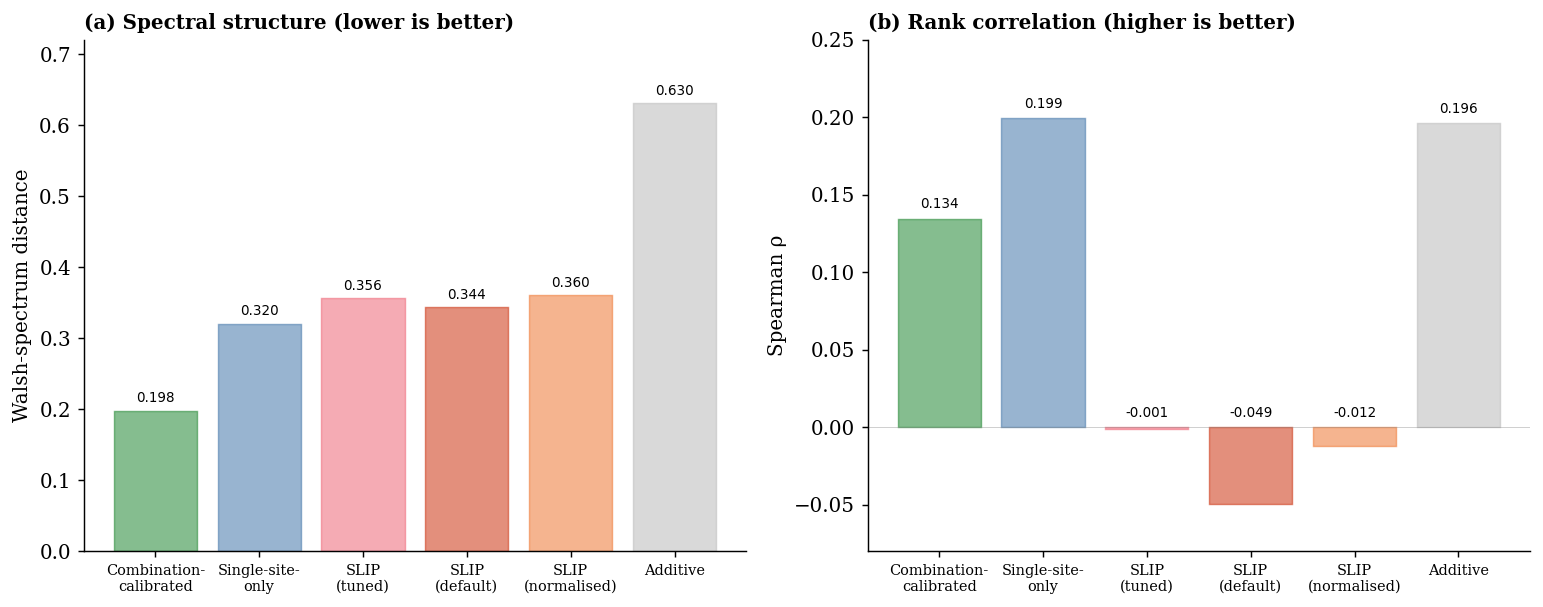

In [6]:
PAL = {
    "calibrated": "#228833",
    "sigmoid": "#4477AA",
    "slip_tuned": "#EE6677",
    "slip_default": "#CC3311",
    "slip_normalised": "#EE7733",
    "additive": "#BBBBBB",
}
LABELS = {
    "calibrated": "Combination-\ncalibrated",
    "sigmoid": "Single-site-\nonly",
    "slip_tuned": "SLIP\n(tuned)",
    "slip_default": "SLIP\n(default)",
    "slip_normalised": "SLIP\n(normalised)",
    "additive": "Additive",
}

gen_order = ["calibrated", "sigmoid", "slip_tuned", "slip_default", "slip_normalised", "additive"]

with plt.rc_context({"font.family": "serif", "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

    # Panel (a): Walsh distance
    ax = axes[0]
    vals = [comp.loc[g, "walsh"] for g in gen_order]
    bars = ax.bar(range(len(gen_order)), vals, color=[PAL[g] for g in gen_order],
                  edgecolor=[PAL[g] for g in gen_order], linewidth=0.8, alpha=0.55)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.008,
                f"{val:.3f}", ha="center", va="bottom", fontsize=7.5,
                fontfamily="sans-serif")
    ax.set_xticks(range(len(gen_order)))
    ax.set_xticklabels([LABELS[g] for g in gen_order], fontsize=8)
    ax.set_ylabel("Walsh-spectrum distance")
    ax.set_title("(a) Spectral structure (lower is better)",
                 fontweight="bold", fontsize=11, loc="left")
    ax.set_ylim(0, 0.72)

    # Panel (b): Spearman
    ax = axes[1]
    vals = [comp.loc[g, "spearman"] for g in gen_order]
    bars = ax.bar(range(len(gen_order)), vals, color=[PAL[g] for g in gen_order],
                  edgecolor=[PAL[g] for g in gen_order], linewidth=0.8, alpha=0.55)
    for bar, val in zip(bars, vals):
        y = max(val, 0) + 0.005
        ax.text(bar.get_x() + bar.get_width() / 2, y,
                f"{val:.3f}", ha="center", va="bottom", fontsize=7.5,
                fontfamily="sans-serif")
    ax.axhline(0, color="grey", ls="-", lw=0.5, alpha=0.4)
    ax.set_xticks(range(len(gen_order)))
    ax.set_xticklabels([LABELS[g] for g in gen_order], fontsize=8)
    ax.set_ylabel("Spearman ρ")
    ax.set_title("(b) Rank correlation (higher is better)",
                 fontweight="bold", fontsize=11, loc="left")
    ax.set_ylim(-0.08, 0.25)

    fig.tight_layout()
    fig.savefig(RESULTS / "slip_comparison_trpb4.png", dpi=200, bbox_inches="tight")
    fig.savefig(RESULTS / "slip_comparison_trpb4.pdf", bbox_inches="tight")
    plt.show()

In [7]:
# Save results
comp.to_csv(RESULTS / "slip_comparison_trpb4.csv")
print(f"Results saved to {RESULTS / 'slip_comparison_trpb4.csv'}")
print()
print(comp.to_string())

Results saved to /Users/tomhill/Uni/research-project/mutascape/output/slip_comparison/slip_comparison_trpb4.csv

                    walsh  spearman   kendall
generator                                    
slip_default     0.343542 -0.049443 -0.033010
slip_normalised  0.360436 -0.011842 -0.008084
slip_tuned       0.355725 -0.001205 -0.000976
calibrated       0.197760  0.134261  0.090123
sigmoid          0.319891  0.199182  0.134323
additive         0.630258  0.195978  0.132045


## Extend SLIP to GB1 and PhoQ

GB1 has a shallow alignment (44 sequences) so the couplings are noisy.
PhoQ uses HATPase_c homologs (1872 sequences). RBD-S309 is excluded:
its 15-site binary encoding is incompatible with SLIP's amino acid Potts model.

In [8]:
# ── SLIP on GB1, TrpB4, PhoQ ──

MSA_CONFIGS = {
    "GB1":   REPO / "data" / "gb1"  / "gb1_msa_couplings.npz",
    "TrpB4": REPO / "data" / "trpb" / "trpb_msa_couplings.npz",
    "PhoQ":  REPO / "data" / "phoq" / "phoq_msa_couplings.npz",
}
WT_OVERRIDES = {"PhoQ": "AVST"}

def build_slip_for(protein, **kwargs):
    frame, design, meta = load_protein(protein)
    msa = np.load(MSA_CONFIGS[protein])
    coupling_matrix = msa["coupling_matrix"]
    sequence = WT_OVERRIDES.get(protein, meta["sequence"])

    L = coupling_matrix.shape[0]
    W = (coupling_matrix + coupling_matrix.transpose(1, 0, 3, 2)) / 2
    W = W.astype(np.float32)

    wt_int = np.array([AA_TO_IDX[aa] for aa in sequence], dtype=int)
    h = np.zeros((L, 20), dtype=np.float32)

    defaults = dict(distance_threshold_for_nearby_residues=1)
    defaults.update(kwargs)
    return potts_model.PottsModel(weight_matrix=W, field_vec=h, wt_seq=wt_int, **defaults)


def score_variants_for(protein, landscape):
    frame, design, meta = load_protein(protein)
    sequence = WT_OVERRIDES.get(protein, meta["sequence"])
    codes = design["codes"]
    shape = tuple(int(s) for s in design["shape"])

    positions = sorted({p for m in frame.loc[frame.depth > 0, "mutations"] for p in m})

    # Derive code → AA from the codes array and stored mutations
    code_to_aa = [{} for _ in positions]
    for i, row in frame.iterrows():
        for site_idx, pos in enumerate(positions):
            cv = int(codes[i, site_idx])
            if cv not in code_to_aa[site_idx]:
                code_to_aa[site_idx][cv] = row.mutations.get(pos, sequence[pos - 1])

    wt_int = np.array([AA_TO_IDX[sequence[p - 1]] for p in positions], dtype=int)
    n = len(frame)
    seqs = np.tile(wt_int, (n, 1))
    for site_idx in range(len(positions)):
        for code_val in range(shape[site_idx]):
            aa = code_to_aa[site_idx][code_val]
            mask = codes[:, site_idx] == code_val
            seqs[mask, site_idx] = AA_TO_IDX[aa]

    raw_fitness = landscape.evaluate(seqs)
    wt_fitness = float(frame.loc[frame.depth == 0, "fitness"].iloc[0])
    return raw_fitness + wt_fitness


slip_all = {}
for protein in ["GB1", "TrpB4", "PhoQ"]:
    base_p = build_slip_for(protein)
    n_aligned = int(np.load(MSA_CONFIGS[protein])["n_aligned"][0])

    frame_p, design_p, _ = load_protein(protein)
    wt_fit = float(frame_p.loc[frame_p.depth == 0, "fitness"].iloc[0])
    exp_singles = frame_p.loc[frame_p.depth == 1]
    frac_adaptive = float((exp_singles.fitness >= wt_fit).mean())

    tuning_p = slip_tuning.get_tuning_kwargs(
        base_p, fraction_adaptive_singles=frac_adaptive, normalize_to_singles=True)
    landscape_p = build_slip_for(protein, **tuning_p)
    values_p = score_variants_for(protein, landscape_p)

    real_p = frame_p.fitness.to_numpy()
    multi_p = np.flatnonzero(frame_p.depth.to_numpy() > 1)
    cal_p = design_p["calibration"][0]
    rows_p = np.setdiff1d(multi_p, cal_p)
    rho, _ = spearmanr(real_p[rows_p], values_p[rows_p])

    slip_all[protein] = float(rho)
    print(f"{protein} ({n_aligned} aligned seqs): SLIP tuned ρ = {rho:.4f}")

print()
print(slip_all)

Untuned landscape stats:
{'epistatic_horizon': np.float32(3.4878123),
 'fraction_adaptive_singles': np.float64(0.9868421052631579),
 'fraction_reciprocal_adaptive_epistasis': np.float64(0.9919393077287814),
 'reciprocal_adaptive_epistasis_effect': np.float32(-6.1414495),
 'std_singles': np.float32(2.1426723)}


GB1 (44 aligned seqs): SLIP tuned ρ = 0.1873
Untuned landscape stats:
{'epistatic_horizon': np.float32(-36.10841),
 'fraction_adaptive_singles': np.float64(0.6710526315789473),
 'fraction_reciprocal_adaptive_epistasis': np.float64(0.4798728813559322),
 'reciprocal_adaptive_epistasis_effect': np.float32(0.1255382),
 'std_singles': np.float32(2.7740078)}


TrpB4 (1590 aligned seqs): SLIP tuned ρ = -0.0012
Untuned landscape stats:
{'epistatic_horizon': np.float32(-27.60216),
 'fraction_adaptive_singles': np.float64(0.6578947368421053),
 'fraction_reciprocal_adaptive_epistasis': np.float64(0.5048231511254019),
 'reciprocal_adaptive_epistasis_effect': np.float32(0.14598556),
 'std_singles': np.float32(2.536328)}


PhoQ (1873 aligned seqs): SLIP tuned ρ = -0.0498

{'GB1': 0.18728450227753732, 'TrpB4': -0.0012050685560823587, 'PhoQ': -0.04984715140776036}


## Rank correlation: Mutascape vs SLIP scatter plots

Side-by-side scatter plots comparing synthetic fitness against experimental
fitness. Each point is one multi-mutant genotype (subsampled for clarity).
Spearman ρ is shown in the title. These panels can serve as manuscript figures.

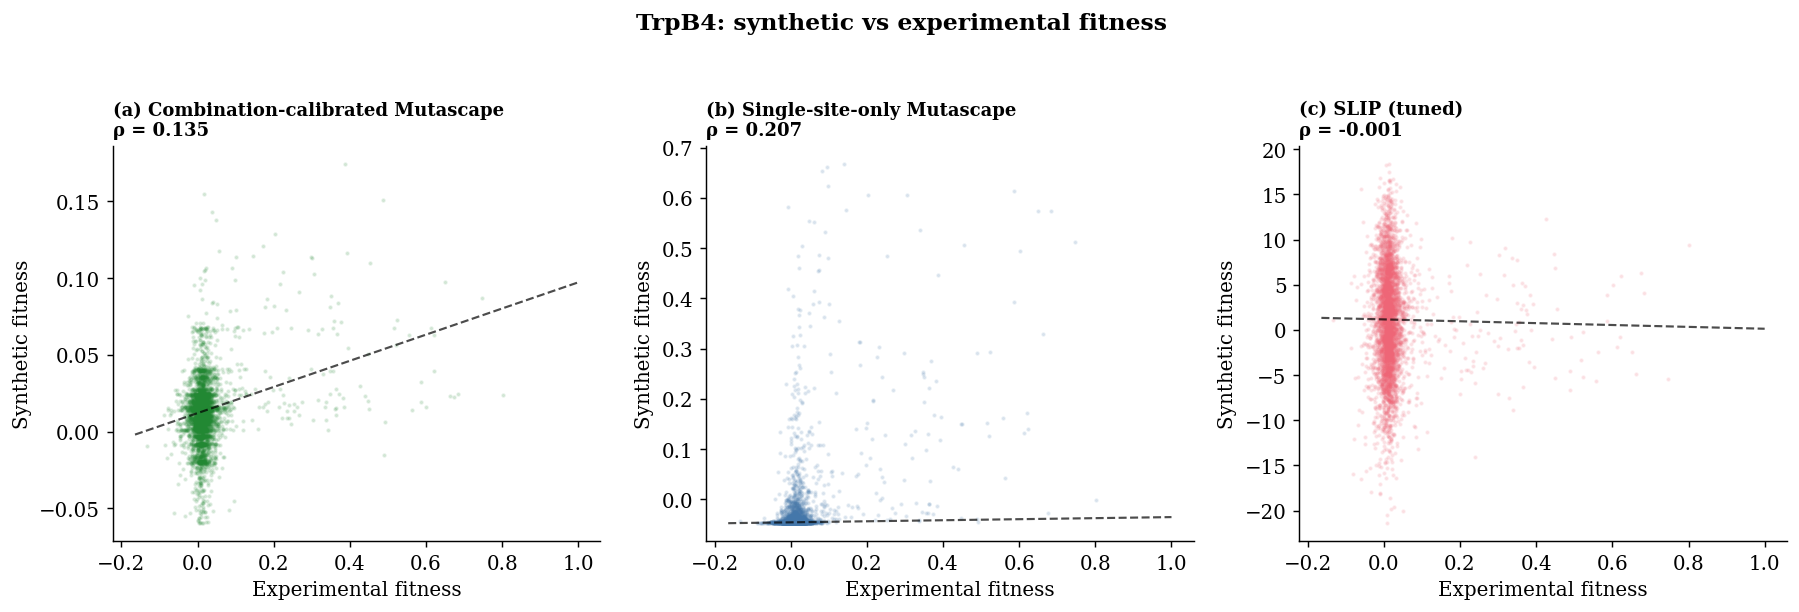

In [9]:
# ── Side-by-side scatter: calibrated vs singles vs SLIP on TrpB4 ──

with plt.rc_context({"font.family": "serif", "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=False)
    rng = np.random.default_rng(42)

    frame_t, design_t, _ = load_protein("TrpB4")
    real_t = frame_t.fitness.to_numpy()
    multi_t = np.flatnonzero(frame_t.depth.to_numpy() > 1)
    cal_t = design_t["calibration"][0]
    rows_t = np.setdiff1d(multi_t, cal_t)
    sub_t = rng.choice(rows_t, size=min(4000, len(rows_t)), replace=False)
    fit_t = rng.choice(rows_t, size=min(5000, len(rows_t)), replace=False)

    landscapes_dir_t = OUT / "TrpB4" / "landscapes"

    panels = [
        ("(a) Combination-calibrated Mutascape", "calibrated_0_0.npy", PAL["calibrated"]),
        ("(b) Single-site-only Mutascape",       "sigmoid_0.npy",      PAL["sigmoid"]),
        ("(c) SLIP (tuned)",                     None,                  PAL["slip_tuned"]),
    ]

    for ax, (title, lfile, colour) in zip(axes, panels):
        if lfile is not None:
            syn = np.load(landscapes_dir_t / lfile)
        else:
            landscape = build_slip_landscape(**tuning_kwargs)
            syn = score_all_variants(landscape)

        rho, _ = spearmanr(real_t[rows_t], syn[rows_t])
        ax.scatter(real_t[sub_t], syn[sub_t], s=2, alpha=0.12, color=colour, rasterized=True)

        slope, intercept, _, _ = theilslopes(syn[fit_t], real_t[fit_t])
        x_line = np.array([real_t[rows_t].min(), real_t[rows_t].max()])
        ax.plot(x_line, slope * x_line + intercept, color="k", lw=1.2, ls="--", alpha=0.7)

        ax.set_xlabel("Experimental fitness")
        ax.set_ylabel("Synthetic fitness")
        ax.set_title(f"{title}\nρ = {rho:.3f}", fontweight="bold", fontsize=10, loc="left")

    fig.suptitle("TrpB4: synthetic vs experimental fitness", fontweight="bold",
                 fontsize=13, y=1.04)
    fig.tight_layout()
    fig.savefig(RESULTS / "scatter_trpb4_comparison.png", dpi=200, bbox_inches="tight")
    fig.savefig(RESULTS / "scatter_trpb4_comparison.pdf", bbox_inches="tight")
    plt.show()

## Mutascape rank correlation across all evaluation proteins

Scatter plots showing Mutascape (calibrated and singles) against experimental
fitness on all four evaluation proteins. RBD-S309 is a 15-site binary
landscape (Omicron substitutions), so SLIP cannot be applied to it, but
Mutascape still produces correlated landscapes.

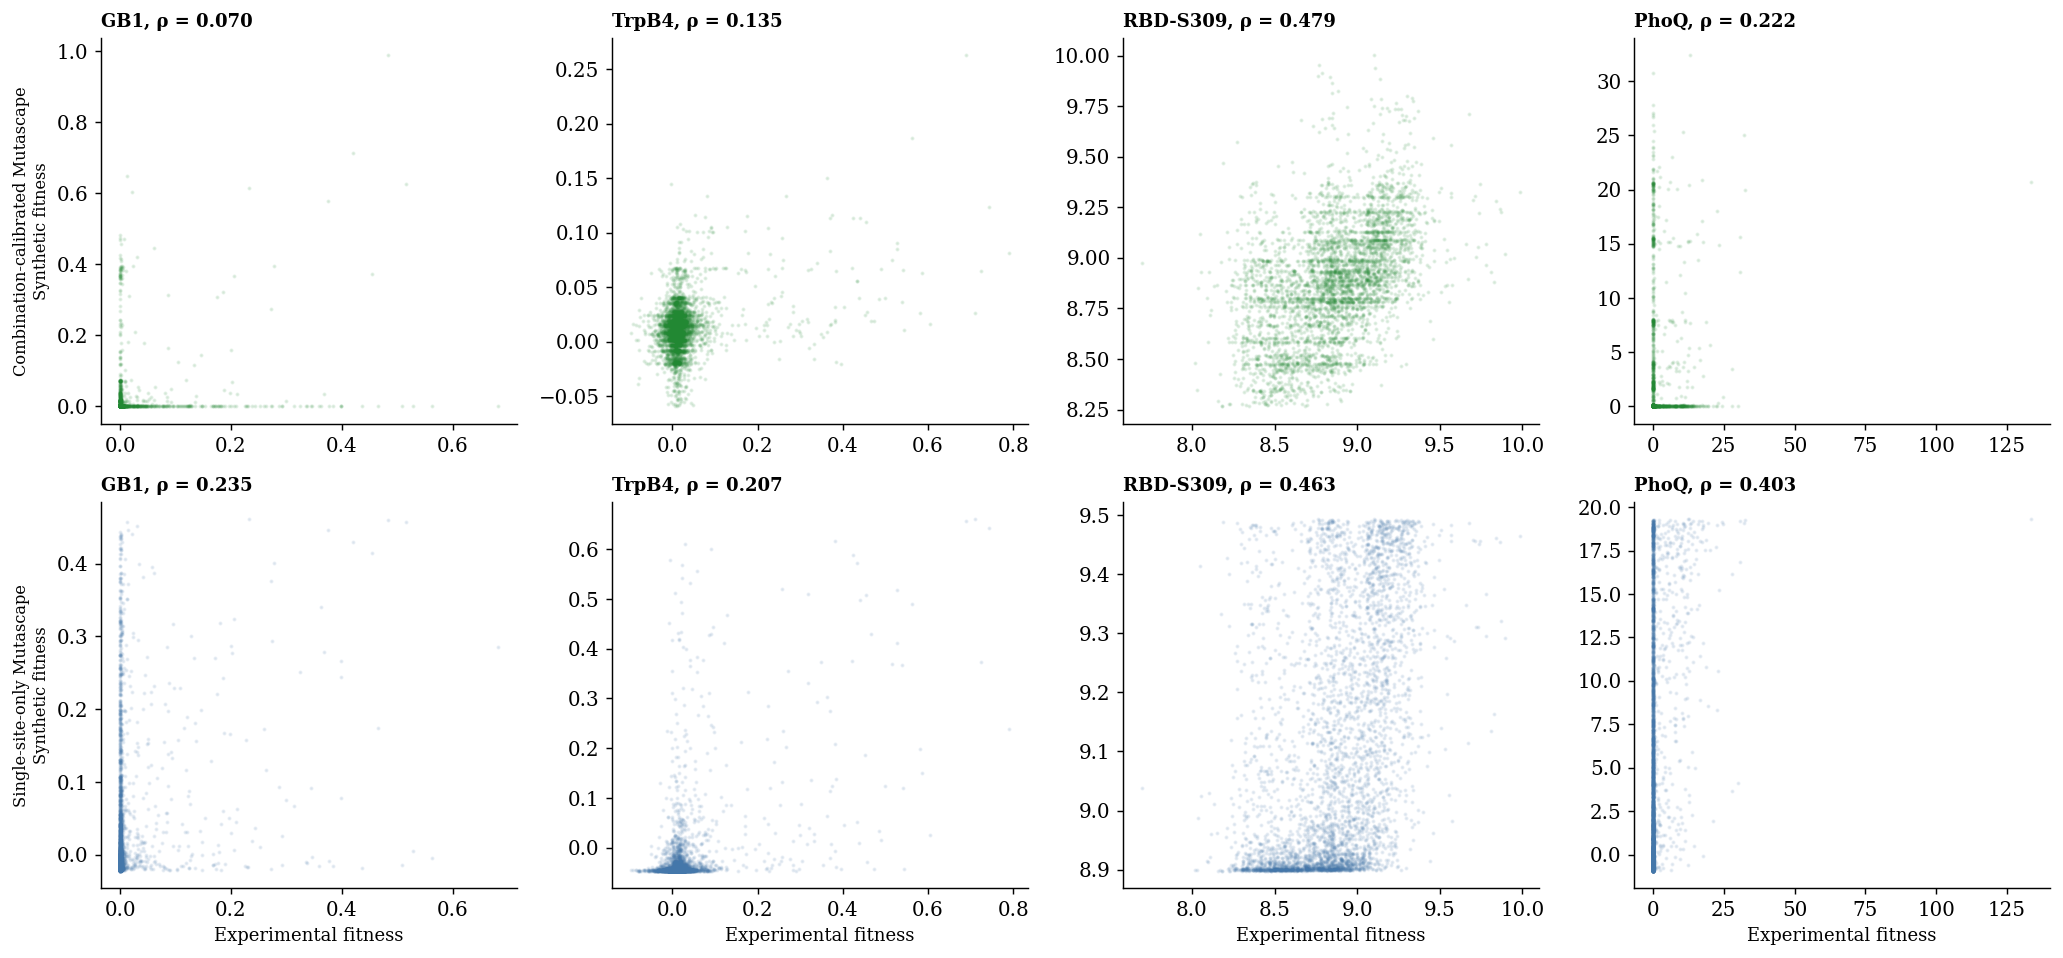

In [10]:
# ── Mutascape scatter grid: 2 rows (calibrated, singles) × 4 proteins ──

PROTEINS = ["GB1", "TrpB4", "RBD-S309", "PhoQ"]
MODELS = [("calibrated", "calibrated_0_0.npy", PAL["calibrated"]),
          ("sigmoid",    "sigmoid_0.npy",      PAL["sigmoid"])]
MODEL_LABELS = {"calibrated": "Combination-calibrated Mutascape",
                "sigmoid": "Single-site-only Mutascape"}

with plt.rc_context({"font.family": "serif", "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
    rng = np.random.default_rng(42)

    for col, protein in enumerate(PROTEINS):
        frame_p, design_p, _ = load_protein(protein)
        real_p = frame_p.fitness.to_numpy()
        multi_p = np.flatnonzero(frame_p.depth.to_numpy() > 1)
        cal_p = design_p["calibration"][0]
        rows_p = np.setdiff1d(multi_p, cal_p)
        sub_p = rng.choice(rows_p, size=min(4000, len(rows_p)), replace=False)
        landscapes_dir_p = OUT / protein / "landscapes"

        for row, (model, lfile, colour) in enumerate(MODELS):
            ax = axes[row, col]
            syn = np.load(landscapes_dir_p / lfile)
            rho, _ = spearmanr(real_p[rows_p], syn[rows_p])

            ax.scatter(real_p[sub_p], syn[sub_p], s=1.5, alpha=0.1, color=colour, rasterized=True)
            ax.set_title(f"{protein}, ρ = {rho:.3f}", fontsize=10, fontweight="bold", loc="left")
            if col == 0:
                ax.set_ylabel(f"{MODEL_LABELS[model]}\nSynthetic fitness", fontsize=9)
            if row == 1:
                ax.set_xlabel("Experimental fitness", fontsize=10)

    fig.tight_layout()
    fig.savefig(RESULTS / "scatter_mutascape_all_proteins.png", dpi=200, bbox_inches="tight")
    fig.savefig(RESULTS / "scatter_mutascape_all_proteins.pdf", bbox_inches="tight")
    plt.show()

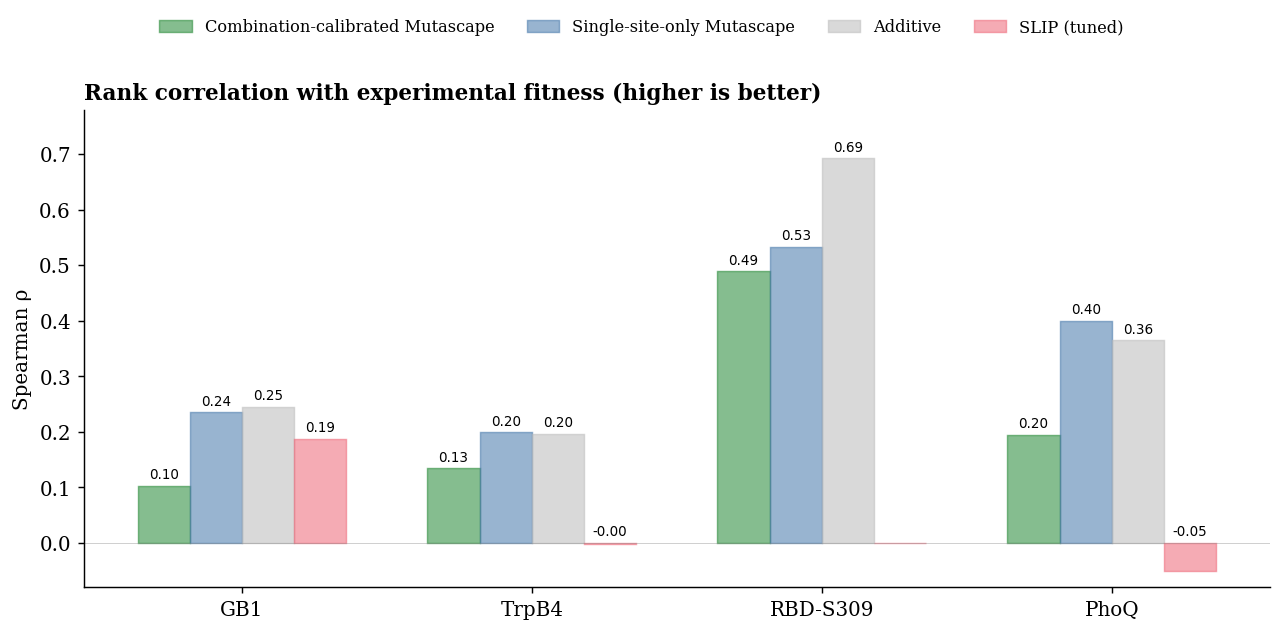

In [11]:
# ── Cross-protein Spearman ρ summary ──

rho_rows = []
for protein in PROTEINS:
    frame_p, design_p, _ = load_protein(protein)
    real_p = frame_p.fitness.to_numpy()
    multi_p = np.flatnonzero(frame_p.depth.to_numpy() > 1)
    cal_p = design_p["calibration"][0]
    rows_p = np.setdiff1d(multi_p, cal_p)
    landscapes_dir_p = OUT / protein / "landscapes"

    for model in ["calibrated", "sigmoid", "additive"]:
        if model == "calibrated":
            paths = sorted(landscapes_dir_p.glob(f"{model}_*_0.npy"))
        else:
            paths = sorted(landscapes_dir_p.glob(f"{model}_*.npy"))
        rhos = []
        for p in paths:
            vals = np.load(p)
            rho, _ = spearmanr(real_p[rows_p], vals[rows_p])
            rhos.append(rho)
        rho_rows.append({"protein": protein, "generator": model, "spearman": np.median(rhos)})

    if protein in slip_all:
        rho_rows.append({"protein": protein, "generator": "slip_tuned",
                         "spearman": slip_all[protein]})

rho_df = pd.DataFrame(rho_rows)

gen_labels = {"calibrated": "Combination-calibrated Mutascape",
              "sigmoid": "Single-site-only Mutascape",
              "additive": "Additive", "slip_tuned": "SLIP (tuned)"}
gen_colours = {"calibrated": PAL["calibrated"], "sigmoid": PAL["sigmoid"],
               "additive": PAL["additive"], "slip_tuned": PAL["slip_tuned"]}
gens = ["calibrated", "sigmoid", "additive", "slip_tuned"]

with plt.rc_context({"font.family": "serif", "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False}):
    fig, ax = plt.subplots(figsize=(10, 4.8))
    x = np.arange(len(PROTEINS))
    width = 0.18

    for i, gen in enumerate(gens):
        subset = rho_df[rho_df.generator == gen]
        vals = [float(subset[subset.protein == p]["spearman"].iloc[0])
                if len(subset[subset.protein == p]) else 0 for p in PROTEINS]
        bars = ax.bar(x + i * width, vals, width, label=gen_labels[gen],
                      color=gen_colours[gen], edgecolor=gen_colours[gen],
                      linewidth=0.8, alpha=0.55)
        for bar, val in zip(bars, vals):
            if val != 0:
                ax.text(bar.get_x() + bar.get_width() / 2, max(val, 0) + 0.008,
                        f"{val:.2f}", ha="center", va="bottom", fontsize=7.5,
                        fontfamily="sans-serif")

    ax.axhline(0, color="grey", ls="-", lw=0.5, alpha=0.4)
    ax.set_xticks(x + 1.5 * width)
    ax.set_xticklabels(PROTEINS, fontsize=11)
    ax.set_ylabel("Spearman ρ")
    ax.set_title("Rank correlation with experimental fitness (higher is better)",
                 fontweight="bold", fontsize=12, loc="left")
    ax.set_ylim(-0.08, 0.78)

    handles, labels = ax.get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False,
               fontsize=9, bbox_to_anchor=(0.5, 1.02))

    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(RESULTS / "spearman_cross_protein.png", dpi=200, bbox_inches="tight")
    fig.savefig(RESULTS / "spearman_cross_protein.pdf", bbox_inches="tight")
    plt.show()

Untuned landscape stats:
{'epistatic_horizon': np.float32(3.4878123),
 'fraction_adaptive_singles': np.float64(0.9868421052631579),
 'fraction_reciprocal_adaptive_epistasis': np.float64(0.9919393077287814),
 'reciprocal_adaptive_epistasis_effect': np.float32(-6.1414495),
 'std_singles': np.float32(2.1426723)}


Untuned landscape stats:
{'epistatic_horizon': np.float32(-36.10841),
 'fraction_adaptive_singles': np.float64(0.6710526315789473),
 'fraction_reciprocal_adaptive_epistasis': np.float64(0.4798728813559322),
 'reciprocal_adaptive_epistasis_effect': np.float32(0.1255382),
 'std_singles': np.float32(2.7740078)}


Untuned landscape stats:
{'epistatic_horizon': np.float32(-27.60216),
 'fraction_adaptive_singles': np.float64(0.6578947368421053),
 'fraction_reciprocal_adaptive_epistasis': np.float64(0.5048231511254019),
 'reciprocal_adaptive_epistasis_effect': np.float32(0.14598556),
 'std_singles': np.float32(2.536328)}


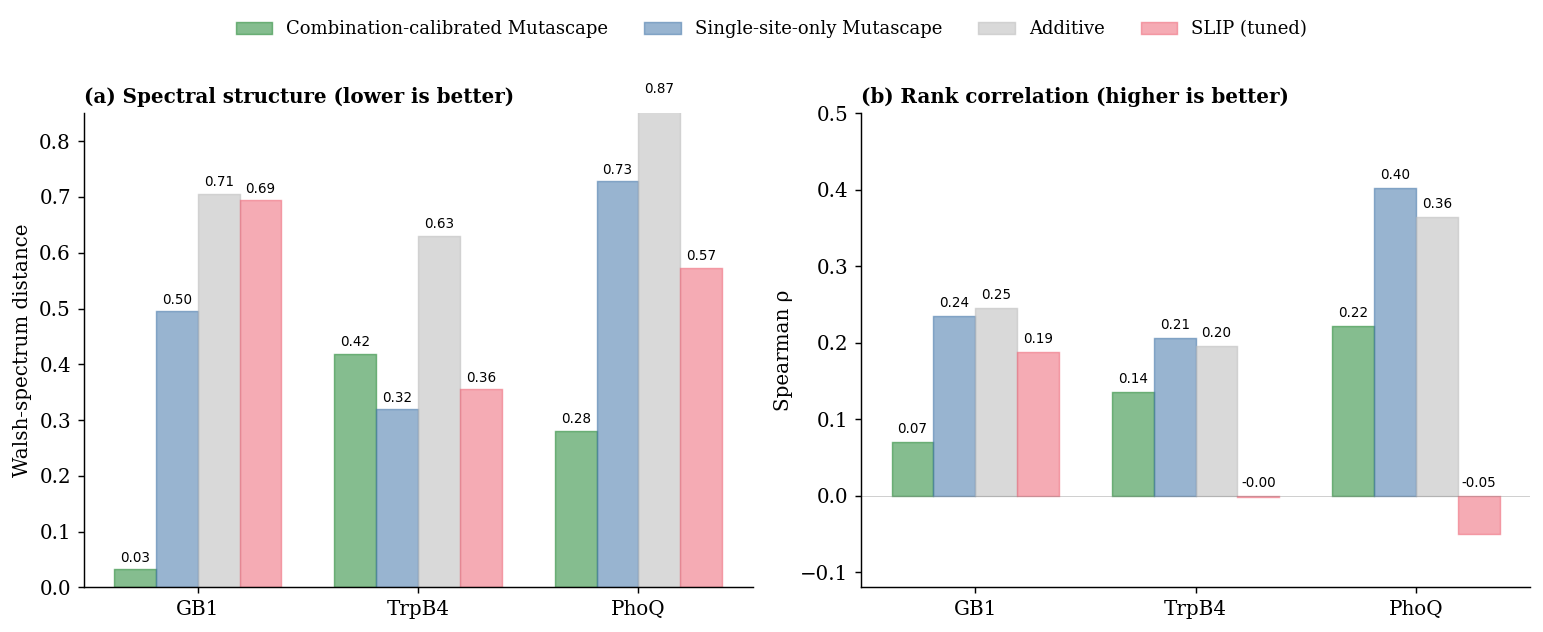

In [12]:
# ── Grouped bar chart: Walsh distance + Spearman ρ across proteins ──

SLIP_PROTEINS = ["GB1", "TrpB4", "PhoQ"]
gen_specs = [
    ("Combination-calibrated Mutascape", "calibrated_0_0.npy", PAL["calibrated"]),
    ("Single-site-only Mutascape",       "sigmoid_0.npy",      PAL["sigmoid"]),
    ("Additive",                         "additive_0.npy",     PAL["additive"]),
    ("SLIP (tuned)",                     None,                  PAL["slip_tuned"]),
]

bar_rows = []
for protein in SLIP_PROTEINS:
    frame_p, design_p, _ = load_protein(protein)
    real_p = frame_p.fitness.to_numpy()
    multi_p = np.flatnonzero(frame_p.depth.to_numpy() > 1)
    cal_p = design_p["calibration"][0]
    rows_p = np.setdiff1d(multi_p, cal_p)
    landscapes_dir_p = OUT / protein / "landscapes"

    has_cubes = "cubes" in design_p
    real_spectrum = walsh_spectrum(real_p, design_p["cubes"]) if has_cubes else None

    for label, lfile, colour in gen_specs:
        if lfile is not None:
            syn = np.load(landscapes_dir_p / lfile)
        else:
            base_p = build_slip_for(protein)
            wt_fit = float(frame_p.loc[frame_p.depth == 0, "fitness"].iloc[0])
            frac_adaptive = float((frame_p.loc[frame_p.depth == 1].fitness >= wt_fit).mean())
            tuning_p = slip_tuning.get_tuning_kwargs(
                base_p, fraction_adaptive_singles=frac_adaptive, normalize_to_singles=True)
            syn = score_variants_for(protein, build_slip_for(protein, **tuning_p))

        rho, _ = spearmanr(real_p[rows_p], syn[rows_p])
        walsh_d = float(np.abs(real_spectrum - walsh_spectrum(syn, design_p["cubes"])).sum()) if has_cubes else np.nan
        bar_rows.append(dict(protein=protein, generator=label, colour=colour,
                             spearman=rho, walsh=walsh_d))

bar_df = pd.DataFrame(bar_rows)
gens = [g[0] for g in gen_specs]
gen_colours = {g[0]: g[2] for g in gen_specs}

with plt.rc_context({"font.family": "serif", "font.size": 11,
                      "axes.spines.top": False, "axes.spines.right": False}):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    x = np.arange(len(SLIP_PROTEINS))
    width = 0.19

    for ax, metric, ylabel, panel_label in [
        (axes[0], "walsh",    "Walsh-spectrum distance",
         "(a) Spectral structure (lower is better)"),
        (axes[1], "spearman", "Spearman ρ",
         "(b) Rank correlation (higher is better)"),
    ]:
        for i, gen in enumerate(gens):
            subset = bar_df[bar_df.generator == gen]
            vals = []
            for p in SLIP_PROTEINS:
                row = subset[subset.protein == p]
                v = float(row[metric].iloc[0]) if len(row) and not np.isnan(row[metric].iloc[0]) else 0
                vals.append(v)
            bars = ax.bar(x + i * width, vals, width, label=gen, color=gen_colours[gen],
                          edgecolor=gen_colours[gen], linewidth=0.8, alpha=0.55)
            for bar, val in zip(bars, vals):
                if val != 0:
                    ax.text(bar.get_x() + bar.get_width() / 2, max(val, 0) + 0.008,
                            f"{val:.2f}", ha="center", va="bottom", fontsize=7.5,
                            fontfamily="sans-serif")

        if metric == "spearman":
            ax.axhline(0, color="grey", ls="-", lw=0.5, alpha=0.4)

        ax.set_xticks(x + 1.5 * width)
        ax.set_xticklabels(SLIP_PROTEINS, fontsize=11)
        ax.set_ylabel(ylabel)
        ax.set_title(panel_label, fontweight="bold", fontsize=11, loc="left")

    axes[0].set_ylim(0, 0.85)
    axes[1].set_ylim(-0.12, 0.5)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, frameon=False,
               fontsize=10, bbox_to_anchor=(0.5, 1.02))

    fig.tight_layout(rect=[0, 0, 1, 0.93])
    fig.savefig(RESULTS / "bar_walsh_spearman.png", dpi=200, bbox_inches="tight")
    fig.savefig(RESULTS / "bar_walsh_spearman.pdf", bbox_inches="tight")
    plt.show()

## Summary

SLIP landscapes were constructed for GB1 (44 aligned sequences), TrpB4 (1590)
and PhoQ (1873), using each protein's MSA-PMI couplings and SLIP's published
tuning procedure. RBD-S309 is excluded because its binary encoding is
incompatible with SLIP's amino acid Potts model.

- **GB1** is the one case where SLIP performs comparably to Mutascape
  (ρ = 0.19 vs 0.10–0.24). GB1's landscape is nearly additive, so even a
  shallow alignment captures enough signal.
- **TrpB4** and **PhoQ**, despite much deeper alignments, give near-zero or
  negative SLIP correlations (ρ ≈ −0.00 and −0.05). Mutascape reaches
  ρ = 0.13–0.40 on the same proteins.
- **Walsh distance** on TrpB4: SLIP (0.34–0.36) sits between the additive
  baseline (0.63) and Mutascape singles-only (0.32). MSA couplings capture
  some epistatic structure but not as much as experimental calibration (0.20).
- **Interpretation**: MSA co-occurrence patterns reproduce the rough
  proportions of epistatic variance but not the specific fitness effects of
  individual mutations. The landscapes look statistically similar in aggregate
  but assign wrong ranks to individual variants. Where epistasis is weak
  (GB1), this matters less.